# Clase 2 · Parte 2 — ¿Qué se inunda, quién vive ahí y sobre qué suelo?

En la Parte 1 armamos, para cada hexágono H3, el terreno (cota, pendiente, aporte, HAND), un K-means y la secuencia +2 / +4 / +6 m. Eso contesta **qué se inunda** (según el terreno).

Ahora cruzamos con dos capas públicas para las otras dos preguntas:

| Pregunta | Capa | Tipo |
|---|---|---|
| ¿Quién vive ahí? | **RENABAP** · Registro Nacional de Barrios Populares (versión 2023, datos.gob.ar) | vector (polígonos) |
| ¿Sobre qué suelo? | **MapBiomas Argentina, Colección 2** · cobertura y uso del suelo anual 1985–2024, 30 m | raster |

Las operaciones son de minería de datos con geometría: *spatial join*, superposición con pesos por área, y pasar un raster categórico a una **tabla** (proporción de cada clase por hexágono).

**Requisito:** haber corrido la Parte 1 (usa `hexes_terreno.parquet`, `centroides_kmeans.csv` y `hand_utm.tif` de la carpeta de Drive `MyDrive/datos_clase2_publico`).

In [1]:
import importlib, subprocess, sys
faltan = [p for p, m in [("h3","h3"),("rasterio","rasterio"),("geopandas","geopandas"),("rasterstats","rasterstats"),
                         ("scikit-learn","sklearn"),("pyarrow","pyarrow")] if importlib.util.find_spec(m) is None]
if faltan: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
import os, time, warnings
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
import rasterio, h3
from rasterio.windows import from_bounds
from rasterio.warp import reproject, Resampling
from shapely.geometry import box
from rasterstats import zonal_stats
warnings.filterwarnings("ignore")
os.environ.setdefault("GDAL_DISABLE_READDIR_ON_OPEN", "EMPTY_DIR")
os.environ.setdefault("CPL_VSIL_CURL_ALLOWED_EXTENSIONS", ".tif")

'.tif'

In [2]:
# ---------------- PARÁMETROS ----------------
BBOX = (-60.85, -31.95, -60.35, -31.45)    # misma ventana que la Parte 1
CRS_METRICO = "EPSG:32720"
H3_RES = 8
ESCENARIOS_M = [2, 4, 6]
# Google Drive: cada notebook corre en una sesión de Colab distinta, así que TODO lo que se
# comparte entre notebooks vive en esta carpeta de Drive (no en el disco local de la sesión).
from google.colab import drive
drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/datos_clase2_publico"   # misma ruta en 01, 02, 03 y 04
os.makedirs(DRIVE_DIR, exist_ok=True)
DATA_DIR = DRIVE_DIR

def chequear(*nombres):
    faltan = [n for n in nombres if not os.path.exists(os.path.join(DATA_DIR, n))]
    if faltan:
        raise FileNotFoundError(f"Faltan en {DATA_DIR}: {faltan}. Corré antes el notebook que los genera.")
chequear("hexes_terreno.parquet", "centroides_kmeans.csv", "hand_utm.tif")

# RENABAP (Registro Nacional de Barrios Populares). Primero el GPKG con todos los atributos;
# si falla, el GeoJSON de argentina.gob.ar (trae solo nombre, ubicación y familias).
RENABAP_URLS = [
    "https://archivo.infraestructura.gob.ar/dataset/ssisu/20231205_info_publica.gpkg",
    "https://www.argentina.gob.ar/sites/default/files/renabap-2023-12-06.geojson",
]
# MapBiomas Argentina, Colección 2: un GeoTIFF por año (1985–2024) para todo el país.
MAPBIOMAS_URL = "https://storage.googleapis.com/mapbiomas-public/initiatives/argentina/collection-2/coverage/argentina_coverage_{anio}.tif"
ANIO = 2024
ANIO_ANTES = 2000

hexes = gpd.read_parquet(os.path.join(DATA_DIR, "hexes_terreno.parquet"))
cent = pd.read_csv(os.path.join(DATA_DIR, "centroides_kmeans.csv"), index_col=0)
GRUPO_RIESGO = int(cent["puntaje_riesgo"].idxmax())
K = len(cent)
print(len(hexes), "hexágonos ·", K, "grupos · grupo de riesgo:", GRUPO_RIESGO)

Mounted at /content/drive
4562 hexágonos · 4 grupos · grupo de riesgo: 0


## 1. RENABAP: quién vive ahí

Según la página oficial del ReNaBaP, el registro reúne información sobre **6.467 barrios populares** (el archivo que bajamos tiene exactamente 6.467 polígonos; el nombre del archivo indica corte 2023-12-05). Cada polígono trae, entre otros: `cantidad_familias_aproximada`, `cantidad_viviendas_aproximadas`, `decada_de_creacion`, `energia_electrica`, `efluentes_cloacales`, `agua_corriente`, `clasificacion_barrio` (villa, asentamiento, conjunto habitacional), `superficie_m2`. Qué significa cada categoría está en el archivo de referencias del mismo dataset (`20231205_info_publica_referencias.csv`).

La descarga es robusta: reintenta, prueba la URL alternativa y guarda una copia local.

In [12]:
import os
import requests
import geopandas as gpd
from shapely.geometry import box

# 1. Eliminación preventiva del GPKG corrupto previo (HTML guardado como binario)
archivo_previo = os.path.join(DATA_DIR, "20231205_info_publica.gpkg")
if os.path.exists(archivo_previo):
    try:
        with open(archivo_previo, "rb") as f:
            if not f.read(16).startswith(b"SQLite format 3"):
                os.remove(archivo_previo)
                print("Se eliminó la copia corrupta de 20231205_info_publica.gpkg.")
    except Exception:
        os.remove(archivo_previo)

# 2. Descarga robusta con User-Agent y descarte de respuestas HTML
def bajar(urls, destino_dir=DATA_DIR, reintentos=3):
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
    }
    for url in urls:
        nombre_archivo = os.path.basename(url)
        destino = os.path.join(destino_dir, nombre_archivo)

        # Si ya existe y pesa más de 100 KB, lo tomamos como válido
        if os.path.exists(destino) and os.path.getsize(destino) > 100_000:
            print("Ya existe archivo válido:", destino)
            return destino

        print("Intentando descargar:", url)
        for i in range(reintentos):
            try:
                with requests.get(url, stream=True, timeout=120, headers=headers) as r:
                    r.raise_for_status()

                    # Evitamos guardar un HTML de error o bloqueo como archivo de datos
                    tipo_contenido = r.headers.get("Content-Type", "")
                    if "text/html" in tipo_contenido:
                        print(f"  Aviso: {url} devolvió página web (HTML), no datos geoespaciales. Saltando a la siguiente...")
                        break

                    with open(destino + ".part", "wb") as f:
                        for chunk in r.iter_content(chunk_size=1024 * 1024):
                            if chunk:
                                f.write(chunk)

                os.replace(destino + ".part", destino)
                print("Descarga exitosa:", destino)
                return destino
            except Exception as e:
                print(f"  Intento {i + 1} falló: {e}")
                if os.path.exists(destino + ".part"):
                    os.remove(destino + ".part")

    raise RuntimeError("No se pudo bajar ninguna fuente. Verificá la conexión o descargalo manualmente.")

# 3. Lectura con GeoPandas y compatibilización de nombres/CRS
ruta = bajar(RENABAP_URLS)
renabap = gpd.read_file(ruta)
print(f"{len(renabap):,} barrios en el archivo nacional · columnas: {list(renabap.columns)}")

if "familias_aproximadas" in renabap.columns and "cantidad_familias_aproximada" not in renabap.columns:
    renabap = renabap.rename(columns={"familias_aproximadas": "cantidad_familias_aproximada"})

# Aseguramos proyección WGS84 para el filtrado espacial con la BBOX
if renabap.crs is None:
    renabap = renabap.set_crs("EPSG:4326")
elif renabap.crs.to_string() != "EPSG:4326":
    renabap = renabap.to_crs("EPSG:4326")

barrios = renabap[renabap.intersects(box(*BBOX))].copy()
print(f"\nEn la ventana de estudio: {len(barrios)} barrios · {barrios.cantidad_familias_aproximada.sum():,.0f} familias (aprox.)")

if "provincia" in barrios.columns and "departamento" in barrios.columns:
    col_id = "id_renabap" if "id_renabap" in barrios.columns else barrios.columns[0]
    display(barrios.groupby(["provincia", "departamento"]).agg(
        barrios=(col_id, "size"),
        familias=("cantidad_familias_aproximada", "sum")
    ))

Se eliminó la copia corrupta de 20231205_info_publica.gpkg.
Intentando descargar: https://archivo.infraestructura.gob.ar/dataset/ssisu/20231205_info_publica.gpkg
  Aviso: https://archivo.infraestructura.gob.ar/dataset/ssisu/20231205_info_publica.gpkg devolvió página web (HTML), no datos geoespaciales. Saltando a la siguiente...
Intentando descargar: https://www.argentina.gob.ar/sites/default/files/renabap-2023-12-06.geojson
Descarga exitosa: /content/drive/MyDrive/datos_clase2_publico/renabap-2023-12-06.geojson
6,467 barrios en el archivo nacional · columnas: ['id_renabap', 'nombre_barrio', 'provincia', 'departamento', 'localidad', 'familias_aproximadas', 'geometry']

En la ventana de estudio: 169 barrios · 32,395 familias (aprox.)


barrios  familias
provincia  departamento                   
Entre Ríos Paraná             70     10790
Santa Fe   Garay               1       110
           La Capital         98     21495

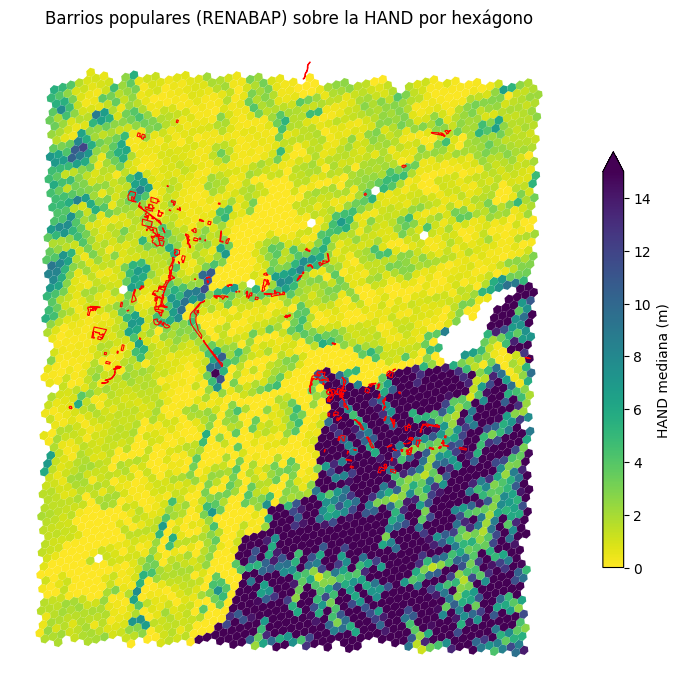

In [13]:
ax = hexes.to_crs(CRS_METRICO).plot(column="hand_mediana", cmap="viridis_r", vmax=15, figsize=(9, 9), legend=True,
                                    legend_kwds={"shrink": 0.6, "label": "HAND mediana (m)"})
barrios.to_crs(CRS_METRICO).plot(ax=ax, facecolor="none", edgecolor="red", lw=0.8)
ax.set_axis_off(); ax.set_title("Barrios populares (RENABAP) sobre la HAND por hexágono"); plt.show()

### Ejercicio 1 — *Spatial join*: barrios → hexágonos

a) Con `gpd.sjoin` (predicado `intersects`), contá cuántos barrios tocan cada hexágono.

b) Un barrio puede caer en varios hexágonos. Repartí sus familias **en proporción al área** que cae en cada hex (`gpd.overlay` en CRS métrico). Verificá que la suma de familias repartidas sea igual (o casi) a la de los barrios de la ventana.

c) ¿Cuántas familias viven en hexágonos del grupo de riesgo?

In [14]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
# a) conteo
j = gpd.sjoin(hexes[["h3", "geometry"]], barrios[["id_renabap", "geometry"]], predicate="intersects")
hexes["n_barrios"] = hexes.h3.map(j.groupby("h3").size()).fillna(0).astype(int)
print("hex con al menos un barrio:", (hexes.n_barrios > 0).sum())

# b) reparto por área
b_m = barrios.to_crs(CRS_METRICO); b_m["area_barrio"] = b_m.area
inter = gpd.overlay(hexes[["h3", "geometry"]].to_crs(CRS_METRICO),
                    b_m[["id_renabap", "cantidad_familias_aproximada", "area_barrio", "geometry"]], how="intersection")
inter["familias"] = inter.cantidad_familias_aproximada * inter.area / inter.area_barrio
hexes["familias"] = hexes.h3.map(inter.groupby("h3").familias.sum()).fillna(0)
print(f"familias repartidas: {hexes.familias.sum():,.0f} · familias de barrios en la ventana: {barrios.cantidad_familias_aproximada.sum():,.0f}")
print("(la diferencia son barrios cortados por el borde o hexágonos descartados en la Parte 1)")

# c) por grupo
por_grupo = hexes.groupby("grupo").agg(hex=("h3", "size"), hex_con_barrio=("n_barrios", lambda s: (s > 0).sum()),
                                       familias=("familias", "sum")).round(0)
por_grupo["rol"] = np.where(por_grupo.index == GRUPO_RIESGO, "RIESGO", "")
por_grupo

hex con al menos un barrio: 282
familias repartidas: 32,348 · familias de barrios en la ventana: 32,395
(la diferencia son barrios cortados por el borde o hexágonos descartados en la Parte 1)


,hex,hex_con_barrio,familias,rol
grupo,,,,
0,1298,76,8958.0,RIESGO
1,1967,107,12812.0,
2,634,57,6560.0,
3,663,42,4018.0,


### 1.1 HAND dentro de cada barrio

El hexágono promedia. Para cada barrio medimos directo sobre el raster de HAND qué fracción de su superficie queda por debajo de 2, 4 y 6 m (`rasterstats.zonal_stats` con estadísticas propias).

In [15]:
HAND_TIF = os.path.join(DATA_DIR, "hand_utm.tif")
def frac_bajo(h):
    return lambda x: float((x.compressed() < h).mean()) if x.count() else np.nan
extra = {f"frac_lt{h}": frac_bajo(h) for h in ESCENARIOS_M}
zs = zonal_stats(barrios.to_crs(CRS_METRICO), HAND_TIF, stats=["median", "count"], add_stats=extra, nodata=-9999, all_touched=True)
zs = pd.DataFrame(zs, index=barrios.index).rename(columns={"median": "hand_mediana_barrio", "count": "n_pix"})
barrios = barrios.join(zs)
cols = ["nombre_barrio", "localidad", "cantidad_familias_aproximada", "hand_mediana_barrio"] + list(extra)
barrios.sort_values("hand_mediana_barrio")[cols].head(15).round(2)

,nombre_barrio,localidad,cantidad_familias_aproximada,hand_mediana_barrio,frac_lt2,frac_lt4,frac_lt6
2760,Loyola,Santa Fe,171,0.00,1.00,1.00,1.0
2724,Los Bañados,Santa Fe,220,0.00,0.99,1.00,1.0
2717,Santa Marta,Santa Fe,176,0.00,1.00,1.00,1.0
2707,Los Hornos,Santa Fe,473,0.00,1.00,1.00,1.0
2740,Schneider,Santa Fe,26,0.03,0.83,0.94,1.0
2693,Los Eucaliptus,San José Del Rincón,12,0.03,0.99,1.00,1.0
2741,Yapeyú,Santa Fe,55,0.03,1.00,1.00,1.0
2710,San José,Santa Fe,94,0.10,0.98,1.00,1.0
6346,Villa Teresa,Santa Fe,24,0.22,1.00,1.00,1.0
2718,La Ranita,Santa Fe,523,0.26,1.00,1.00,1.0


## 2. MapBiomas: sobre qué suelo

MapBiomas Argentina Colección 2 publica un GeoTIFF por año (1985–2024), píxel de ~30 m, con códigos de clase. El archivo nacional es grande, pero está **teselado con overviews**, así que leemos solo la ventana por HTTP.

Códigos de la leyenda de la Colección 2 (documento oficial "Códigos y paleta de colores… colección 2"), agrupados para la clase:

| grupo para la clase | códigos MapBiomas Col. 2 |
|---|---|
| bosque | 3 bosques cerrados · 4 bosques abiertos · 6 bosques inundables |
| herbáceo inundable | 11 herbáceas inundables |
| otra vegetación natural | 12 herbáceas · 63 mosaico arbustos y herbáceas · 66 arbustales cerrados · 77 arbustales abiertos · 73 turberas |
| agropecuario | 9 silvicultura · 15 pasturas · 18 agricultura · 19 cultivos temporarios · 36 cultivos perennes · 21 mosaico de usos |
| urbano | 24 áreas urbanas |
| otra sin vegetación | 25 otras áreas no vegetadas |
| agua | 33 ríos, lagunas, lagos y océano · 34 hielo y nieve |
| no observado | 27 |

In [16]:
GRUPOS = {
    "bosque": [3, 4, 6], "herbaceo_inundable": [11], "otra_veg_natural": [12, 63, 66, 77, 73],
    "agropecuario": [9, 15, 18, 19, 36, 21], "urbano": [24], "otra_sin_veg": [25], "agua": [33, 34], "no_observado": [27],
}
NOMBRES = list(GRUPOS)
LUT = np.zeros(256, dtype=np.uint8)           # 0 = sin dato
for i, g in enumerate(NOMBRES, start=1):
    for c in GRUPOS[g]: LUT[c] = i
COLORES_LU = {"bosque": "#1f8d49", "herbaceo_inundable": "#519799", "otra_veg_natural": "#d6bc74",
              "agropecuario": "#ffefc3", "urbano": "#d4271e", "otra_sin_veg": "#db4d4f", "agua": "#2532e4", "no_observado": "#ffffff"}

def leer_mapbiomas(anio, bbox=BBOX, reintentos=3):
    local = os.path.join(DATA_DIR, f"mapbiomas_c2_{anio}_ventana.tif")
    if os.path.exists(local):
        with rasterio.open(local) as s: return s.read(1), s.transform, s.crs
    url = "/vsicurl/" + MAPBIOMAS_URL.format(anio=anio)
    for i in range(reintentos):
        try:
            with rasterio.open(url) as s:
                w = from_bounds(*bbox, s.transform).round_offsets().round_lengths()
                a = s.read(1, window=w); tr = s.window_transform(w); crs = s.crs
            prof = dict(driver="GTiff", height=a.shape[0], width=a.shape[1], count=1, dtype=a.dtype, crs=crs, transform=tr, compress="deflate")
            with rasterio.open(local, "w", **prof) as d: d.write(a, 1)
            return a, tr, crs
        except Exception as e:
            print(f"  intento {i+1} falló: {e}"); time.sleep(3 * (i + 1))
    raise RuntimeError("No se pudo leer MapBiomas por HTTP. Alternativas: bajar el GeoTIFF del año (ver README) o exportar desde GEE.")

t0 = time.time()
mb, mb_tr, mb_crs = leer_mapbiomas(ANIO)
print(f"MapBiomas {ANIO}: {mb.shape} píxeles, {mb_crs}, {time.time()-t0:.1f} s")
print("códigos presentes:", dict(zip(*np.unique(mb, return_counts=True))))

MapBiomas 2024: (1855, 1855) píxeles, EPSG:4326, 1.1 s
códigos presentes: {np.int32(3): np.int64(25404), np.int32(4): np.int64(60954), np.int32(6): np.int64(196988), np.int32(9): np.int64(5236), np.int32(11): np.int64(1434805), np.int32(12): np.int64(159889), np.int32(15): np.int64(378260), np.int32(19): np.int64(581412), np.int32(24): np.int64(329134), np.int32(25): np.int64(8467), np.int32(33): np.int64(256958), np.int32(36): np.int64(2978), np.int32(66): np.int64(13), np.int32(77): np.int64(527)}


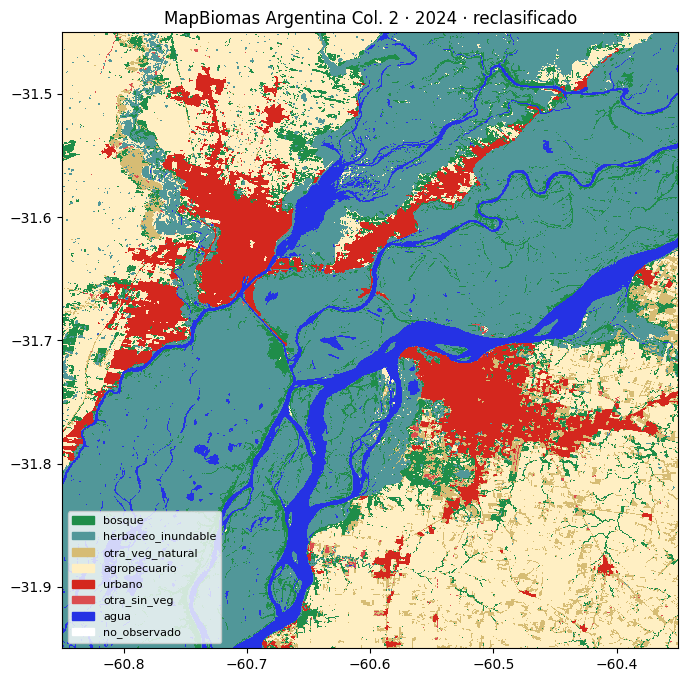

In [17]:
from matplotlib.colors import ListedColormap
lu = LUT[np.clip(mb, 0, 255)]
cmap = ListedColormap(["#000000"] + [COLORES_LU[n] for n in NOMBRES])
ext = (mb_tr.c, mb_tr.c + mb_tr.a * mb.shape[1], mb_tr.f + mb_tr.e * mb.shape[0], mb_tr.f)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(lu, cmap=cmap, vmin=0, vmax=len(NOMBRES), extent=ext, interpolation="nearest")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLORES_LU[n], label=n) for n in NOMBRES], loc="lower left", fontsize=8)
ax.set_title(f"MapBiomas Argentina Col. 2 · {ANIO} · reclasificado"); plt.show()

### Ejercicio 2 — Reclasificar el raster a una tabla: proporción de cada clase por hexágono

a) **Método píxel → hex.** Calculá el centro de cada píxel, su celda H3 y hacé un `groupby` para obtener la proporción de cada grupo de uso por hexágono (columnas `lu_bosque`, `lu_urbano`, …).

b) **Método estadística zonal.** Con `zonal_stats(..., categorical=True)` sobre los polígonos de 200 hexágonos al azar, calculá lo mismo y comparalo con (a). ¿Por qué no da exactamente igual?

c) Agregá la columna `uso_dominante` (la clase de mayor proporción).

In [18]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
# a) píxel -> hex
t0 = time.time()
filas, cols = np.indices(mb.shape)
lon = mb_tr.c + (cols.ravel() + 0.5) * mb_tr.a; lat = mb_tr.f + (filas.ravel() + 0.5) * mb_tr.e
celda = [h3.latlng_to_cell(la, lo, H3_RES) for la, lo in zip(lat, lon)]
px = pd.DataFrame({"h3": celda, "grupo_lu": lu.ravel()})
px = px[px.h3.isin(set(hexes.h3)) & (px.grupo_lu > 0)]
prop = pd.crosstab(px.h3, px.grupo_lu, normalize="index")
prop.columns = ["lu_" + NOMBRES[c - 1] for c in prop.columns]
for n in NOMBRES:
    if "lu_" + n not in prop: prop["lu_" + n] = 0.0
LU_COLS = ["lu_" + n for n in NOMBRES]
hexes = hexes.drop(columns=[c for c in hexes.columns if c.startswith("lu_") or c == "uso_dominante"]).merge(
    prop[LU_COLS], left_on="h3", right_index=True, how="left")
print(f"píxel→hex en {time.time()-t0:.1f} s")

# b) zonal stats categórica sobre una muestra (en el CRS del raster: EPSG:4326)
mb_lu_tif = os.path.join(DATA_DIR, f"mapbiomas_c2_{ANIO}_reclas.tif")
with rasterio.open(mb_lu_tif, "w", driver="GTiff", height=lu.shape[0], width=lu.shape[1], count=1, dtype="uint8",
                   crs=mb_crs, transform=mb_tr, nodata=0) as d: d.write(lu, 1)
muestra = hexes.sample(200, random_state=0)
zs = zonal_stats(muestra, mb_lu_tif, categorical=True, nodata=0)
zs = pd.DataFrame(zs, index=muestra.index).fillna(0)
zs = zs.div(zs.sum(axis=1), axis=0); zs.columns = ["lu_" + NOMBRES[int(c) - 1] for c in zs.columns]
dif = (zs - muestra[zs.columns]).abs().max().round(3)
print("máxima diferencia absoluta por clase (zonal vs píxel→hex):"); print(dif)
# No da igual porque zonal_stats incluye un píxel si su CENTRO cae dentro del polígono (o si lo toca, con all_touched),
# y en (a) asignamos el píxel por la celda H3 de su centro: los bordes se reparten distinto. Son diferencias chicas.

# c) uso dominante
hexes["uso_dominante"] = hexes[LU_COLS].idxmax(axis=1).str.replace("lu_", "")
hexes.uso_dominante.value_counts()

píxel→hex en 6.1 s
máxima diferencia absoluta por clase (zonal vs píxel→hex):
lu_bosque                0.000
lu_otra_veg_natural      0.000
lu_agropecuario          0.001
lu_herbaceo_inundable    0.000
lu_urbano                0.000
lu_agua                  0.001
lu_otra_sin_veg          0.000
dtype: float64


,count
uso_dominante,
herbaceo_inundable,2090
agropecuario,1462
urbano,480
agua,260
bosque,171
otra_veg_natural,98
otra_sin_veg,1


### Ejercicio 3 — Hexágonos → uso del suelo, por grupo de K-means

¿De qué está hecho el grupo de riesgo? Calculá la composición media de uso del suelo de cada grupo. Separá el grupo de riesgo en **agua** (el río mismo, que obviamente está "bajo y drena") y **tierra**: ¿cuánto de la tierra del grupo de riesgo es urbana, herbácea inundable, agropecuaria?

In [19]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
comp = hexes.groupby("grupo")[LU_COLS].mean().mul(100).round(1)
comp.index = [f"{g} {'(RIESGO)' if g == GRUPO_RIESGO else ''}" for g in comp.index]
display(comp)

riesgo = hexes[hexes.grupo == GRUPO_RIESGO]
tierra = riesgo[riesgo.lu_agua < 0.5]
print(f"Grupo de riesgo: {len(riesgo)} hex · {len(riesgo)-len(tierra)} son mayormente agua · {len(tierra)} son tierra")
print("Uso dominante de los hex de TIERRA del grupo de riesgo:")
display(tierra.uso_dominante.value_counts())
print(f"Familias (RENABAP, reparto por área) en hex de tierra del grupo de riesgo: {tierra.familias.sum():,.0f}")

,lu_bosque,lu_herbaceo_inundable,lu_otra_veg_natural,lu_agropecuario,lu_urbano,lu_otra_sin_veg,lu_agua,lu_no_observado
0 (RIESGO),6.5,57.1,2.0,16.0,4.5,0.1,13.9,0.0
1,8.3,55.1,0.9,20.0,9.4,0.1,6.1,0.0
2,15.0,11.8,12.6,42.1,14.7,0.6,3.3,0.0
3,5.4,1.6,13.7,62.8,15.5,0.6,0.4,0.0


Grupo de riesgo: 1298 hex · 130 son mayormente agua · 1168 son tierra
Uso dominante de los hex de TIERRA del grupo de riesgo:


,count
uso_dominante,
herbaceo_inundable,820
agropecuario,231
urbano,57
bosque,24
agua,20
otra_veg_natural,16


Familias (RENABAP, reparto por área) en hex de tierra del grupo de riesgo: 8,610


### Ejercicio 4 — ¿Creció la ciudad sobre lo bajo?

Leé MapBiomas para `ANIO_ANTES` y repetí la proporción urbana por hexágono. Compará el cambio de superficie urbana (km²) en hexágonos que entran con +2 m contra los que no entran ni con +6 m.

In [20]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
mb0, tr0, _ = leer_mapbiomas(ANIO_ANTES)
assert mb0.shape == mb.shape
urb0 = pd.Series((LUT[np.clip(mb0, 0, 255)] == NOMBRES.index("urbano") + 1).ravel())
urb1 = pd.Series((lu == NOMBRES.index("urbano") + 1).ravel())
df = pd.DataFrame({"h3": celda, "u0": urb0.values, "u1": urb1.values}).groupby("h3")[["u0", "u1"]].mean()
hexes["urb_antes"] = hexes.h3.map(df.u0); hexes["urb_ahora"] = hexes.h3.map(df.u1)
AREA_HEX_KM2 = h3.average_hexagon_area(H3_RES, unit="km^2")
hexes["d_urb_km2"] = (hexes.urb_ahora - hexes.urb_antes) * AREA_HEX_KM2
hexes["clase_subida"] = np.select([hexes.adentro_2m, hexes.adentro_6m], ["entra con +2 m", "entra con +4/+6 m"], "no entra con +6 m")
display(hexes.groupby("clase_subida").agg(hex=("h3", "size"),
        urbano_antes_km2=("urb_antes", lambda s: s.sum() * AREA_HEX_KM2),
        urbano_ahora_km2=("urb_ahora", lambda s: s.sum() * AREA_HEX_KM2),
        cambio_km2=("d_urb_km2", "sum")).round(1))

,hex,urbano_antes_km2,urbano_ahora_km2,cambio_km2
clase_subida,,,,
entra con +2 m,2368,92.9,97.9,5.1
entra con +4/+6 m,920,77.0,83.5,6.5
no entra con +6 m,1274,132.4,143.2,10.7


## 3. Síntesis: la tabla de la pregunta guía

Para cada escenario, a nivel de píxel (más fino que el hex):

- **qué se inunda:** km² con HAND < h;
- **sobre qué suelo:** de esos km², cuántos son urbanos, herbáceo inundable, agua (MapBiomas re-proyectado a la grilla del DEM);
- **quién vive ahí:** barrios con al menos 10 % de su superficie bajo h, y familias aproximadas (familias × fracción del barrio bajo h).

Las familias son un orden de magnitud: el RENABAP da familias *aproximadas* por barrio y suponemos que se reparten parejo dentro del barrio.

In [21]:
with rasterio.open(HAND_TIF) as s:
    hand = s.read(1).astype(float); hand[hand == -9999] = np.nan; T = s.transform; shape = s.shape
lu_utm = np.zeros(shape, dtype=np.uint8)
reproject(lu, lu_utm, src_transform=mb_tr, src_crs=mb_crs, dst_transform=T, dst_crs=CRS_METRICO,
          resampling=Resampling.nearest, src_nodata=0, dst_nodata=0)
CELDA_KM2 = abs(T.a * T.e) / 1e6

filas_ = []
for h in ESCENARIOS_M:
    m = hand < h
    fila = {"escenario": f"+{h} m", "km2_bajo_h": np.nansum(m) * CELDA_KM2}
    for n in ["urbano", "herbaceo_inundable", "agropecuario", "agua"]:
        fila[f"km2_{n}"] = np.sum(m & (lu_utm == NOMBRES.index(n) + 1)) * CELDA_KM2
    b = barrios[barrios[f"frac_lt{h}"] >= 0.10]
    fila["barrios_>=10%"] = len(b)
    fila["familias_aprox"] = (barrios.cantidad_familias_aproximada * barrios[f"frac_lt{h}"].fillna(0)).sum()
    filas_.append(fila)
sintesis = pd.DataFrame(filas_).set_index("escenario").round(1)
sintesis

,km2_bajo_h,km2_urbano,km2_herbaceo_inundable,km2_agropecuario,km2_agua,barrios_>=10%,familias_aprox
escenario,,,,,,,
+2 m,1277.6,66.6,768.7,208.6,164.6,97,10841.3
+4 m,1620.7,101.5,933.9,291.6,166.8,121,17248.7
+6 m,1788.6,129.2,971.6,348.3,168.1,129,22361.0


In [22]:
# ¿Cómo son esos barrios? Servicios y década de creación (solo si el archivo trae esos atributos: GPKG)
if "efluentes_cloacales" in barrios.columns:
    b6 = barrios[barrios.frac_lt6 >= 0.10]
    print(f"Barrios con >=10 % bajo +6 m: {len(b6)} de {len(barrios)} en la ventana\n")
    for col in ["efluentes_cloacales", "agua_corriente", "decada_de_creacion", "clasificacion_barrio"]:
        t = pd.concat([b6[col].value_counts(normalize=True).rename("bajo +6 m"),
                       barrios[col].value_counts(normalize=True).rename("todos (ventana)")], axis=1).mul(100).round(1)
        display(t)
else:
    print("El archivo alternativo no trae servicios ni década: usá el GPKG (ver README).")

El archivo alternativo no trae servicios ni década: usá el GPKG (ver README).


In [23]:
# Guardamos en Drive (DATA_DIR = DRIVE_DIR) lo que leen 03 y 04
hexes.to_parquet(os.path.join(DATA_DIR, "hexes_terreno_renabap_mapbiomas.parquet"))
sintesis.to_csv(os.path.join(DATA_DIR, "sintesis_escenarios.csv"))
barrios.drop(columns="geometry").to_csv(os.path.join(DATA_DIR, "barrios_ventana_hand.csv"), index=False)
barrios.to_parquet(os.path.join(DATA_DIR, "barrios_ventana_hand.parquet"))   # con geometría, para el 03
faltan_sol = [c_ for c_ in ["familias", "uso_dominante"] if c_ not in hexes]
if faltan_sol: print("OJO: faltan", faltan_sol, "→ corré las celdas de solución de los ejercicios 1 y 2 antes de guardar (el 04 las usa).")
print("Guardado en", DATA_DIR, "· columnas:", list(hexes.columns))


Guardado en /content/drive/MyDrive/datos_clase2_publico · columnas: ['h3', 'n_pix', 'cota_media', 'pendiente_media', 'aporte_log_max', 'hand_mediana', 'frac_hand_lt2', 'frac_hand_lt4', 'frac_hand_lt6', 'geometry', 'grupo', 'adentro_2m', 'adentro_4m', 'adentro_6m', 'n_barrios', 'familias', 'lu_bosque', 'lu_herbaceo_inundable', 'lu_otra_veg_natural', 'lu_agropecuario', 'lu_urbano', 'lu_otra_sin_veg', 'lu_agua', 'lu_no_observado', 'uso_dominante', 'urb_antes', 'urb_ahora', 'd_urb_km2', 'clase_subida']


## 4. Hoja de cuatro líneas (entrega de la semana)

1. **Qué grupos hay esta semana:** (nombres puestos desde el mapa, no desde el número de cluster).
2. **Qué se lee cuando el río sube:** qué grupo entra primero con +2, +4, +6 m.
3. **Qué quedó más firme que la clase 1:** (pista: franja vs HAND).
4. **Qué todavía no se puede decir:** (pistas: defensas y bombas, edificios en el DSM, el río real no sube parejo, el RENABAP da familias aproximadas, MapBiomas tiene píxel de 30 m y no ve un pasillo).

**Lo que no hay que escribir:** "este barrio se va a inundar". Esto es terreno + registros, no un pronóstico.

### 4. Hoja de cuatro líneas (entrega de la semana)

1. **Qué grupos hay esta semana:**  
   Valle de inundación/planicie baja (cota mínima y drena al cauce), terrazas bajas/humedales ribereños, planicie media y barranca/tierras altas (cota elevada y fuerte pendiente).

2. **Qué se lee cuando el río sube:**  
   A **+2 m** se anega primero el valle de inundación más cercano al cauce, a **+4 m** se expande sobre las terrazas bajas, y a **+6 m** compromete la planicie media, quedando a salvo las barrancas.

3. **Qué quedó más firme que la clase 1:**  
   Usamos **HAND** (*Height Above Nearest Drainage*), demostrando que el agua drena por gravedad y el anegamiento depende del desnivel relativo a la red de drenaje, no de la simple distancia al río.